In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.utils.class_weight import compute_class_weight

import warnings
warnings.filterwarnings('ignore')

In [11]:
# Dataset Loading

df = pd.read_csv(
    r"C:\DEV\Fake Job Prediction\Fake Job Dataset\fake_job_postings.csv")

base_path = r"C:\DEV\Fake Job Prediction\Fake Job Dataset\images"
df['webpage_screenshot'] = df.apply(
    lambda x: f"{base_path}/{x['fraudulent']}/{x['job_id']}.png",
    axis=1
)

print("Dataset loaded successfully.")
print("Shape:", df.shape)


Dataset loaded successfully.
Shape: (17880, 19)


In [39]:
# Dataset Inspection

df.head()

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

In [13]:
missing_values = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df) * 100
).sort_values(ascending=False)

missing_df = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
})

missing_df[missing_df['Missing Values'] > 0]

,Missing Values,Percentage
benefits,7212,40.335570
company_profile,3308,18.501119
department,11547,64.580537
description,1,0.005593
employment_type,3471,19.412752
function,6455,36.101790
industry,4903,27.421700
location,346,1.935123
required_education,8105,45.329978
required_experience,7050,39.429530


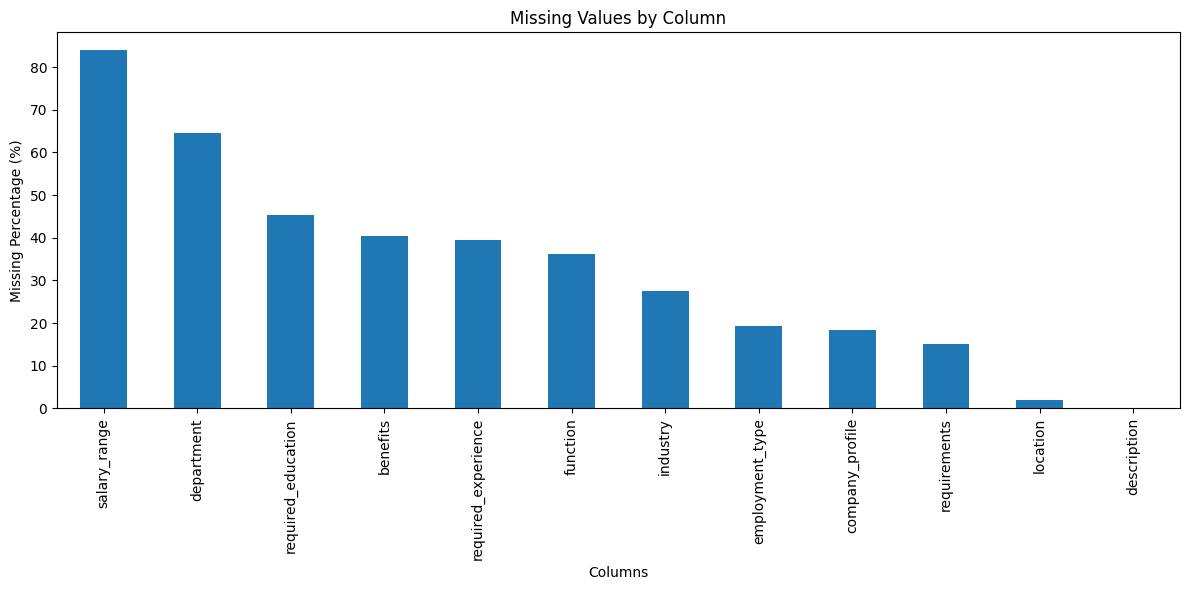

In [14]:
plt.figure(figsize=(12, 6))

missing_percentage[missing_percentage > 0].plot(kind='bar')

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [17]:
# 0 → Real job  # 1 → Fraudulent job

print(df['fraudulent'].value_counts())

fraudulent
0    17014
1      866
Name: count, dtype: int64


In [18]:
print(
    df['fraudulent'].value_counts(normalize=True) * 100
)

fraudulent
0    95.1566
1     4.8434
Name: proportion, dtype: float64


In [26]:
for col in binary_features:

    fraud_rate = df.groupby(col)['fraudulent'].mean() * 100

    print(f"\nFraud rate based on {col}:")
    print(fraud_rate)


Fraud rate based on telecommuting:
telecommuting
0    4.686496
1    8.344198
Name: fraudulent, dtype: float64

Fraud rate based on has_company_logo:
has_company_logo
0    15.928962
1     1.990155
Name: fraudulent, dtype: float64

Fraud rate based on has_questions:
has_questions
0    6.778169
1    2.843494
Name: fraudulent, dtype: float64


In [30]:
text_features = [
    'title',
    'location',
    'department',
    'company_profile',
    'description',
    'requirements',
    'benefits'
]

df['text'] = (
    df[text_features]
    .fillna("")
    .agg(" ".join, axis=1)
)

df[['title', 'description', 'text','department','company_profile','requirements','benefits','fraudulent',]].head()

,title,description,text,department,company_profile,requirements,benefits,fraudulent
0,Marketing Intern,"Food52, a fast-growing, James Beard Award-winn...","Marketing Intern US, NY, New York Marketing We...",Marketing,"We're Food52, and we've created a groundbreaki...",Experience with content management systems a m...,NaN,0
1,Customer Service - Cloud Video Production,Organised - Focused - Vibrant - Awesome!Do you...,"Customer Service - Cloud Video Production NZ, ...",Success,"90 Seconds, the worlds Cloud Video Production ...",What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0
2,Commissioning Machinery Assistant (CMA),"Our client, located in Houston, is actively se...","Commissioning Machinery Assistant (CMA) US, IA...",NaN,Valor Services provides Workforce Solutions th...,Implement pre-commissioning and commissioning ...,NaN,0
3,Account Executive - Washington DC,THE COMPANY: ESRI – Environmental Systems Rese...,"Account Executive - Washington DC US, DC, Wash...",Sales,Our passion for improving quality of life thro...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0
4,Bill Review Manager,JOB TITLE: Itemization Review ManagerLOCATION:...,"Bill Review Manager US, FL, Fort Worth SpotSo...",NaN,SpotSource Solutions LLC is a Global Human Cap...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0


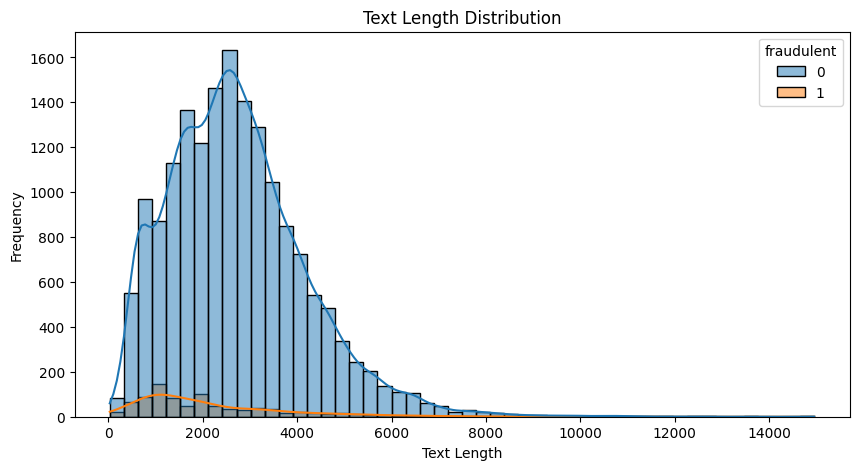

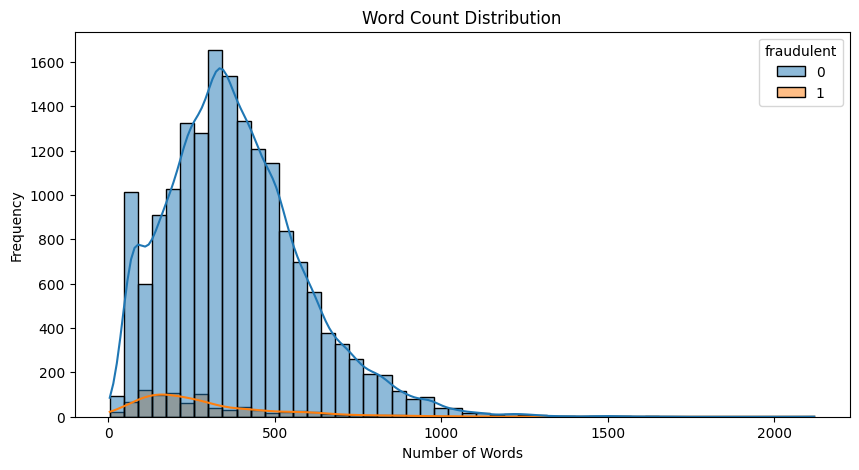

In [33]:
df['text_length'] = df['text'].str.len()

df['word_count'] = df['text'].str.split().str.len()

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='text_length',
    hue='fraudulent',
    bins=50,
    kde=True
)

plt.title("Text Length Distribution")
plt.xlabel("Text Length")
plt.ylabel("Frequency")

plt.show()

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='word_count',
    hue='fraudulent',
    bins=50,
    kde=True
)

plt.title("Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

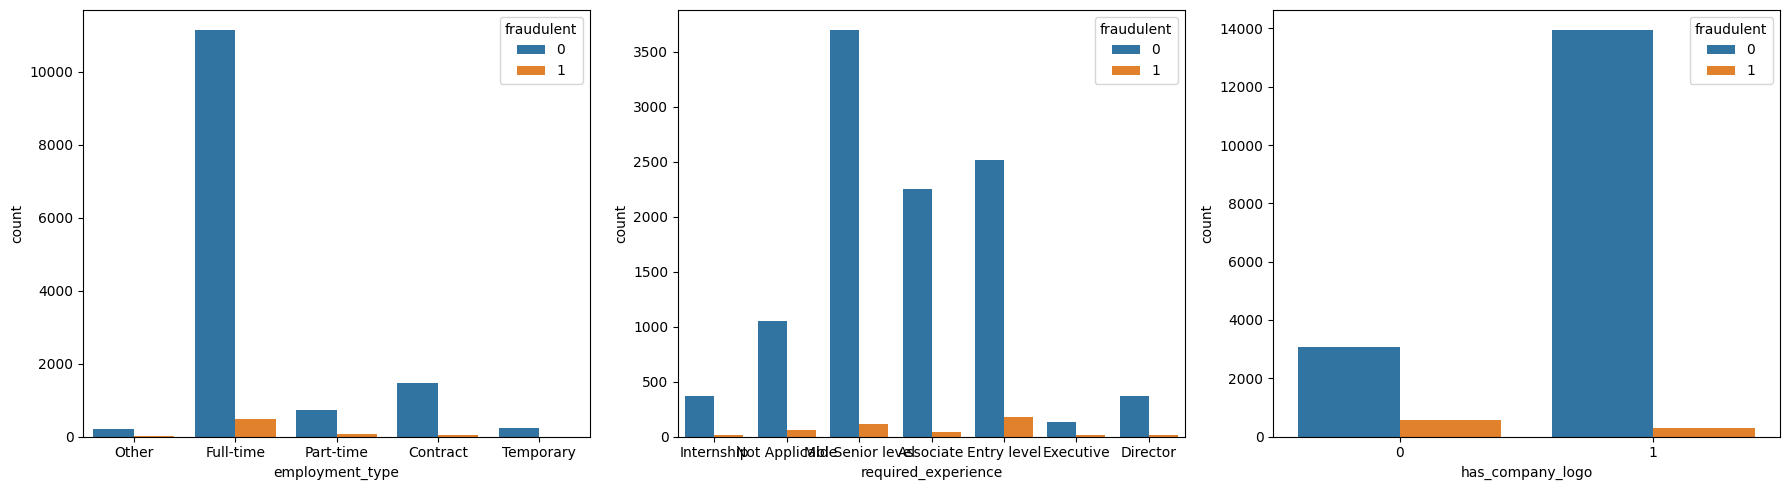

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=df, x='employment_type', hue='fraudulent', ax=axes[0])
sns.countplot(data=df, x='required_experience', hue='fraudulent', ax=axes[1])
sns.countplot(data=df, x='has_company_logo', hue='fraudulent', ax=axes[2])

plt.tight_layout()
plt.show()

In [35]:
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df['fraudulent'],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)



In [36]:
tfidf_vectorizer = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1, 2)
)

tfidf_features_train = tfidf_vectorizer.fit_transform(
    train_df['text']
).toarray()

tfidf_features_test = tfidf_vectorizer.transform(
    test_df['text']
).toarray()

In [37]:
bow_vectorizer = CountVectorizer(
    max_features=500,
    binary=True
)

bow_features_train = bow_vectorizer.fit_transform(
    train_df['text']
).toarray()

bow_features_test = bow_vectorizer.transform(
    test_df['text']
).toarray()